# Market making vs. momentum on tick data

This notebook drives the **C++ event-driven engine** from Python (pybind11) to compare two
opposite ways of trading the same crypto tape:

| | Market maker | Momentum |
|---|---|---|
| Earns | the spread, from mean reversion | trends |
| Order type | passive limit orders (maker) | aggressive market orders (taker) |
| Main risk | adverse selection, inventory | whipsaw, costs on every flip |
| Trades | thousands of small fills | a handful of large ones |

Every backtest replays individual trades through a simulated exchange with order latency,
a queue-position fill model, maker/taker fees and slippage. Strategies cannot see the future:
orders go live only after latency and can only fill on later trades (this is unit-tested).

**Data.** Put a Binance trades file in `data/trades/` (`python tools/download_binance_trades.py
--symbol BTCUSDT --date 2026-10-01`) and set `DATA` below. Without one, the notebook uses a
**synthetic tape**, which tests the pipeline but says nothing about real markets.

In [1]:
import sys, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
for p in (ROOT, ROOT / "engine" / "python", ROOT / "tools"):
    sys.path.insert(0, str(p))

import pandas as pd
import trading_engine as te
import research
from research import plotting as P

pd.set_option("display.float_format", lambda v: f"{v:,.2f}" if abs(v) >= 1 or v == 0 else f"{v:.4f}")
%matplotlib inline

In [2]:
# Use the first real Binance file if there is one, otherwise a synthetic tape.
real = sorted((ROOT / "data" / "trades").glob("*USDT-trades-*.csv"))
DATA = real[0] if real else ROOT / "data" / "trades" / "SYNTH-BTCUSDT.csv"
if not DATA.exists():
    from generate_synthetic_trades import generate, write_csv
    write_csv(generate(2_000_000, seed=1), DATA)

t0 = time.perf_counter()
trades = te.load_trades(DATA)
print(f"{DATA.name}: {len(trades):,} trades, {trades.index[0]} -> {trades.index[-1]} "
      f"(loaded by the C++ parser in {time.perf_counter() - t0:.2f}s)")
print("SYNTHETIC DATA: results illustrate the pipeline only" if "SYNTH" in DATA.name else "Real market data")
trades.head()

SYNTH-BTCUSDT.csv: 2,000,000 trades, 2025-10-01 00:00:00.046291+00:00 -> 2025-10-02 11:28:01.648472+00:00 (loaded by the C++ parser in 0.58s)
SYNTHETIC DATA: results illustrate the pipeline only


,ts_us,price,qty,buyer_is_maker,trade_id
time,,,,,
2025-10-01 00:00:00.046291+00:00,1759276800046291,"65,002.68",0.0043,False,1
2025-10-01 00:00:00.046741+00:00,1759276800046741,"64,996.99",0.0120,True,2
2025-10-01 00:00:00.095690+00:00,1759276800095690,"64,996.16",0.0157,True,3
2025-10-01 00:00:00.189894+00:00,1759276800189894,"64,996.33",0.0011,True,4
2025-10-01 00:00:00.277820+00:00,1759276800277820,"65,003.02",0.0211,False,5


## Shared assumptions

Both strategies get the same costs, latency and risk limits, and the same maximum
exposure (0.1 BTC), so their PnL is comparable.

In [3]:
COSTS = dict(maker_bps=1.0, taker_bps=4.0, slippage_bps=1.0, latency_ms=5, max_position=0.2)
MM_FIXED = {"order_qty": 0.01, "max_inventory": 0.1}
MOM_FIXED = {"order_qty": 0.1}
te.config_to_dict(te.make_config(**COSTS))

{'cash': 100000.0,
 'max_position': 0.2,
 'max_order_qty': 1.0,
 'max_open_orders': 20,
 'latency_ms': 5.0,
 'maker_bps': 1.0,
 'taker_bps': 4.0,
 'slippage_bps': 1.0,
 'touch_ratio': 0.25,
 'sample_sec': 60.0}

## 1. Default parameters on the whole tape

A first look, before any tuning.

In [4]:
table, base = research.compare(trades, [
    ("market_maker", "market_maker", MM_FIXED),
    ("momentum", "momentum", MOM_FIXED),
], **COSTS)
table[["total_pnl", "fees", "pnl_per_notional_bps", "max_drawdown", "fills", "traded_notional", "wall_seconds"]]

,total_pnl,fees,pnl_per_notional_bps,max_drawdown,fills,traded_notional,wall_seconds
run,,,,,,,
market_maker,"-3,574.16","3,810.63",-0.9379,"3,574.41",134892,"38,106,291.72",0.2130
momentum,"2,158.67",98.33,87.82,162.44,20,"245,815.93",0.0350


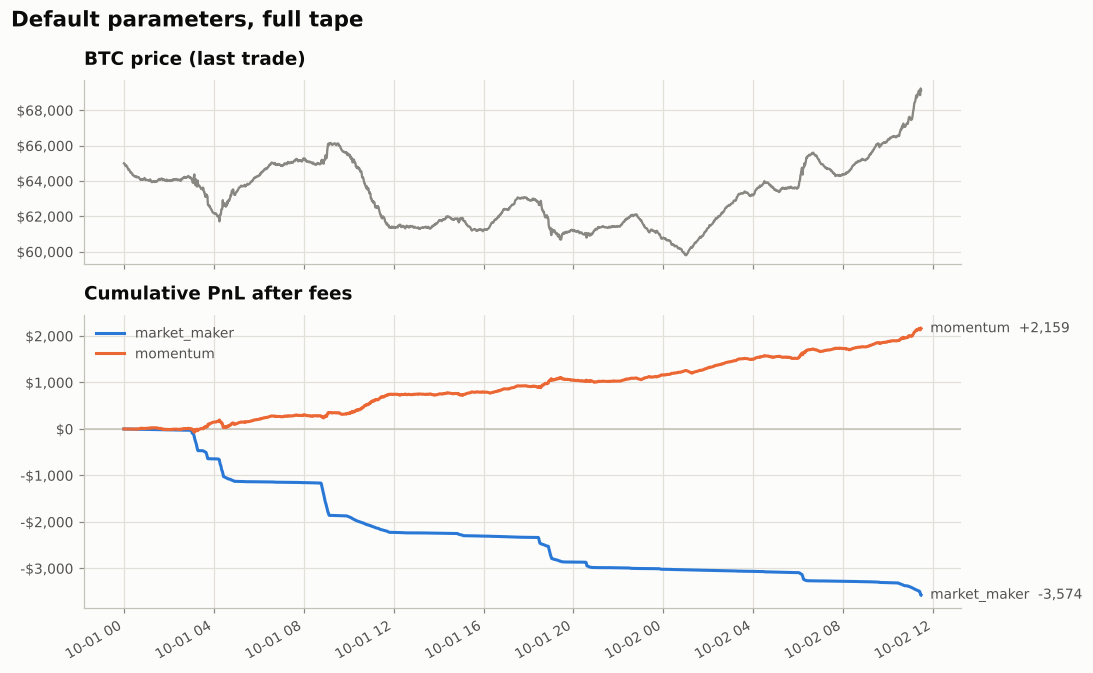

In [5]:
P.pnl_over_time(base, "Default parameters, full tape");

## 2. What the market maker actually does

A typical one-minute window: the grey dots are market trades; the lines are the maker's
bid and ask, which follow a fair-value estimate and lean against inventory. Triangles are fills.

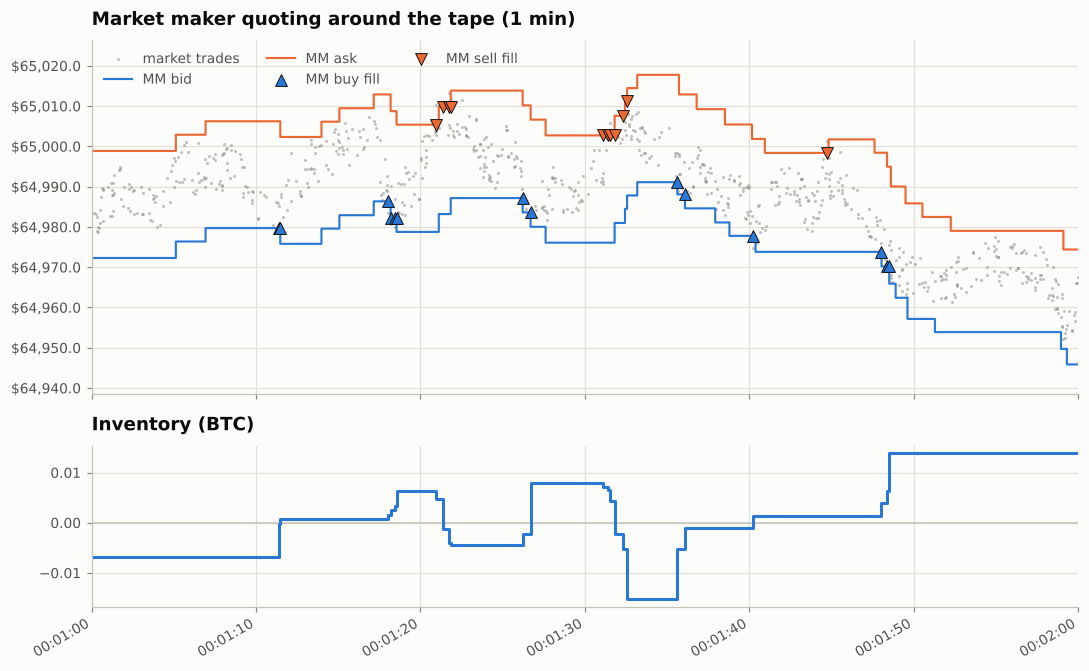

In [6]:
mm = te.backtest(trades, "market_maker", MM_FIXED, record_signals=True, **COSTS)
start = P.typical_window(mm.fills, minutes=1)
P.mm_microstructure(trades, mm, start, minutes=1);

## 3. Parameter sweeps with an out-of-sample check

Tuning on the same data you report on overstates results. Here parameters are chosen on
the **first half** of the tape and judged on the **second half**, which the selection never saw.
Each sweep runs in parallel threads: the C++ engine releases Python's GIL.

In [7]:
from research.report import MM_GRID, MOM_GRID

t0 = time.perf_counter()
mm_split = research.select_and_validate(trades, "market_maker", MM_GRID, min_fills=200, base_params=MM_FIXED, **COSTS)
mom_split = research.select_and_validate(trades, "momentum", MOM_GRID, min_fills=10, base_params=MOM_FIXED, **COSTS)
n = 2 * (len(mm_split.in_sample) + len(mom_split.in_sample))
print(f"{n} backtests in {time.perf_counter() - t0:.1f}s")
print("market maker selected:", mm_split.best_params)
print("momentum selected:    ", mom_split.best_params)

354 backtests in 12.9s
market maker selected: {'base_half_spread_bps': 5.0, 'inventory_skew_bps': 0.0, 'vol_multiplier': 3.0}
momentum selected:     {'bar_seconds': 15.0, 'fast_bars': 20.0, 'slow_bars': 60.0, 'band_bps': 5.0}


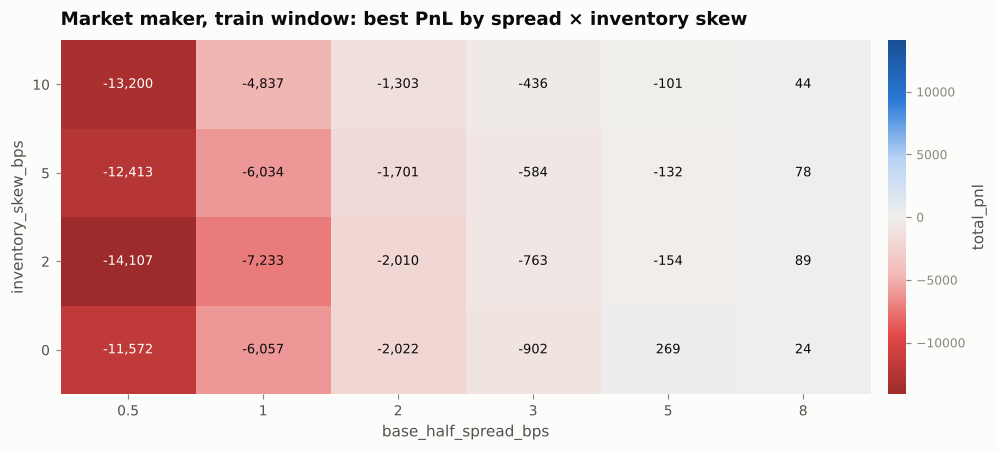

In [8]:
P.sweep_heatmap(mm_split.in_sample, "base_half_spread_bps", "inventory_skew_bps", "total_pnl",
                title="Market maker, train window: best PnL by spread × inventory skew");

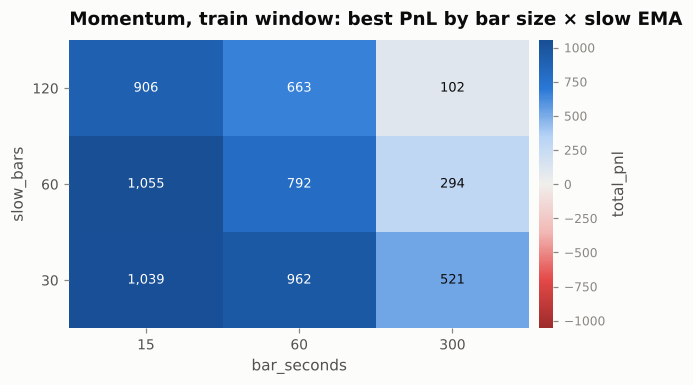

In [9]:
P.sweep_heatmap(mom_split.in_sample, "bar_seconds", "slow_bars", "total_pnl",
                title="Momentum, train window: best PnL by bar size × slow EMA");

**Is the sweep finding something real?** Each dot is one parameter set. If in-sample
ranking predicts out-of-sample ranking (rank correlation near +1), the parameters capture a
stable effect. Near zero means the "best" parameters were mostly luck.

,rank corr (IS vs OOS),OOS percentile of selected
market_maker,0.9840,100.00
momentum,0.8803,93.83


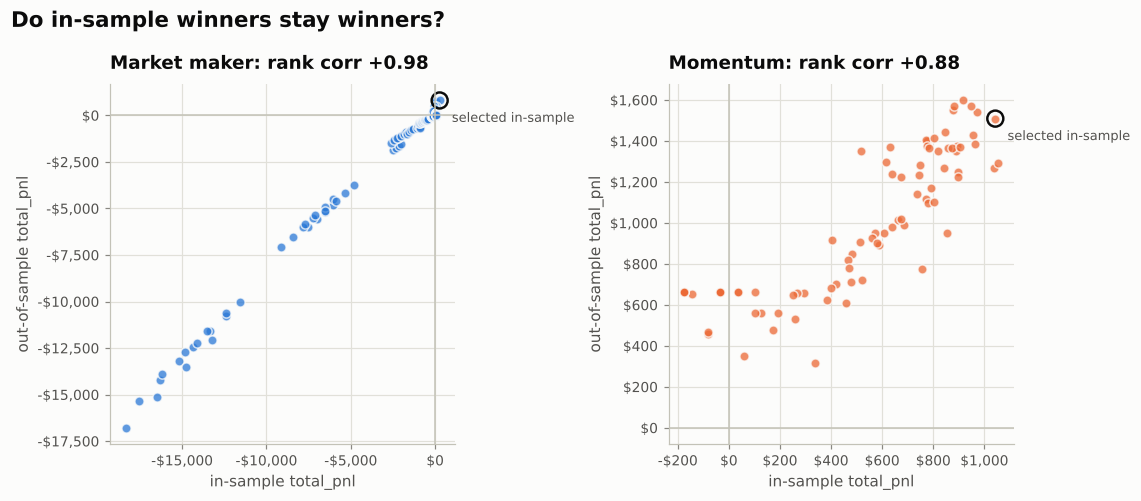

In [10]:
P.in_vs_out_of_sample({"Market maker": mm_split, "Momentum": mom_split});
pd.DataFrame({
    "rank corr (IS vs OOS)": [mm_split.rank_correlation(), mom_split.rank_correlation()],
    "OOS percentile of selected": [mm_split.oos_percentile_of_best(), mom_split.oos_percentile_of_best()],
}, index=["market_maker", "momentum"])

## 4. Head-to-head on the untouched test window

In [11]:
_, test = research.time_split(trades, 0.5)
mm_params = {**MM_FIXED, **mm_split.best_params}
mom_params = {**MOM_FIXED, **mom_split.best_params}
oos_table, oos = research.compare(test, [
    ("market_maker", "market_maker", mm_params),
    ("momentum", "momentum", mom_params),
], **COSTS)
oos_table[["total_pnl", "fees", "pnl_per_notional_bps", "max_drawdown", "fills", "traded_notional", "max_abs_position"]]

,total_pnl,fees,pnl_per_notional_bps,max_drawdown,fills,traded_notional,max_abs_position
run,,,,,,,
market_maker,800.77,31.16,25.70,208.86,1038,"311,587.23",0.0993
momentum,"1,509.28",62.65,96.36,54.07,13,"156,625.95",0.1000


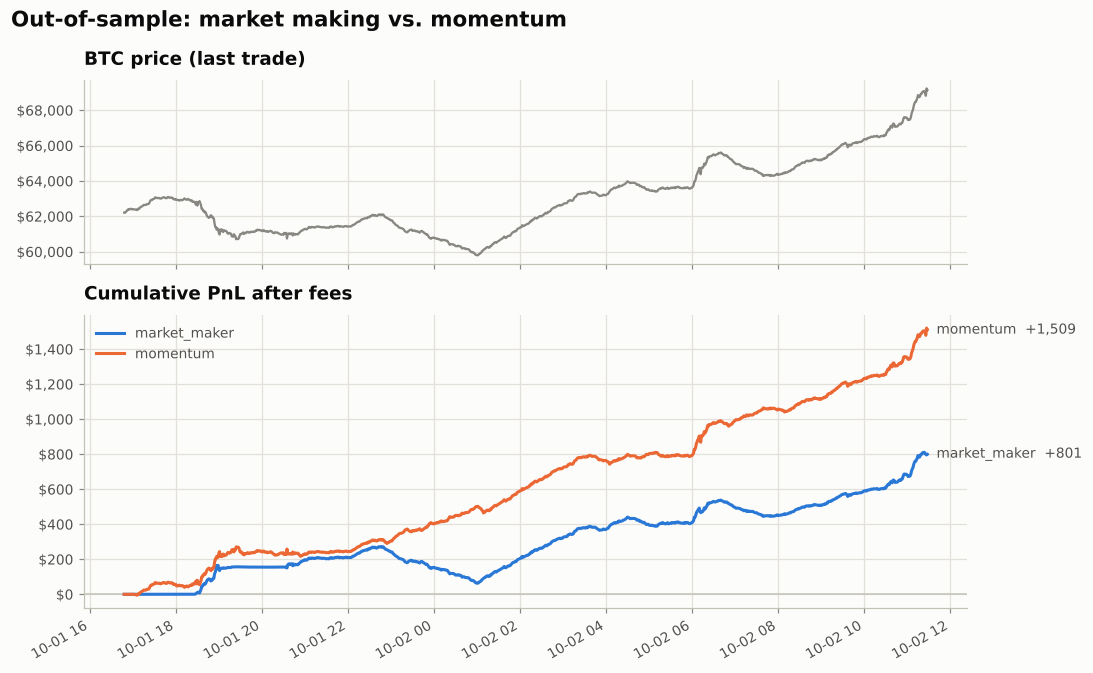

In [12]:
P.pnl_over_time(oos, "Out-of-sample: market making vs. momentum");

## 5. What the result depends on

Market making earns a few basis points per trade at most, so the exchange fee tier can
decide whether it makes money at all. Latency matters because a slow maker's quotes
sit stale while the price moves through them.

,maker_bps,total_pnl,fees,pnl_per_notional_bps,fills
0,-1.00,863.09,-31.16,27.70,1038
1,-0.5000,847.51,-15.58,27.20,1038
2,0.00,831.93,0.00,26.70,1038
3,0.2500,824.14,7.79,26.45,1038
4,0.5000,816.35,15.58,26.20,1038
5,1.00,800.77,31.16,25.70,1038
6,1.50,785.19,46.74,25.20,1038
7,2.00,769.61,62.32,24.70,1038


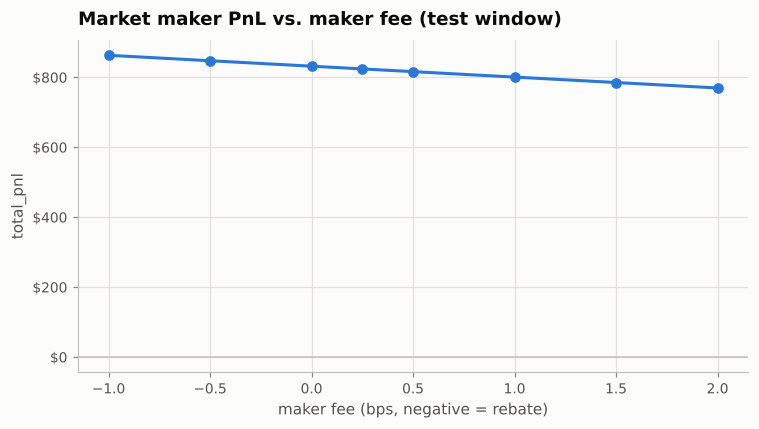

In [13]:
fees = research.config_sweep(test, "market_maker", mm_params, "maker_bps", [-1, -0.5, 0, 0.25, 0.5, 1, 1.5, 2],
                             **{k: v for k, v in COSTS.items() if k != "maker_bps"})
P.sensitivity(fees, "maker_bps", "total_pnl", color=P.BLUE, xlabel="maker fee (bps, negative = rebate)",
              title="Market maker PnL vs. maker fee (test window)");
fees[["maker_bps", "total_pnl", "fees", "pnl_per_notional_bps", "fills"]]

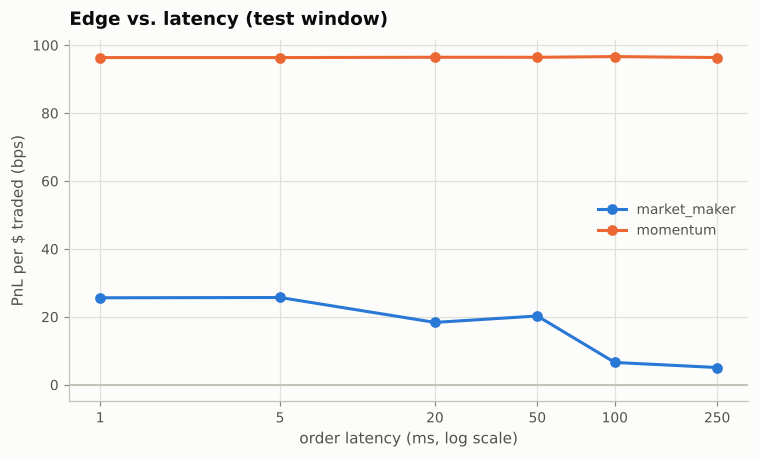

In [14]:
lat = [1, 5, 20, 50, 100, 250]
no_lat = {k: v for k, v in COSTS.items() if k != "latency_ms"}
lat_mm = research.config_sweep(test, "market_maker", mm_params, "latency_ms", lat, **no_lat)
lat_mom = research.config_sweep(test, "momentum", mom_params, "latency_ms", lat, **no_lat)
fig, ax = P.plt.subplots(figsize=(7, 4))
P.sensitivity(lat_mm, "latency_ms", "pnl_per_notional_bps", label="market_maker", color=P.BLUE, ax=ax, mark_breakeven=False)
P.sensitivity(lat_mom, "latency_ms", "pnl_per_notional_bps", label="momentum", color=P.ORANGE, ax=ax, mark_breakeven=False)
ax.set_xscale("log"); ax.set_xticks(lat, [str(v) for v in lat]); ax.minorticks_off()
ax.set_xlabel("order latency (ms, log scale)"); ax.set_ylabel("PnL per $ traded (bps)")
ax.set_title("Edge vs. latency (test window)");

## 6. Summary

Computed from the runs above, so it stays correct when you switch to real data.

In [15]:
m, s = oos["market_maker"].metrics, oos["momentum"].metrics
days = (test.index[-1] - test.index[0]).total_seconds() / 86400
lines = [
    f"Test window: {days:.2f} days, {len(test):,} market trades.",
    f"Market maker: {m['fills']:,} fills, PnL {m['total_pnl']:+,.0f} after {m['fees']:,.0f} fees "
    f"({m['pnl_per_notional_bps']:+.2f} bps per $ traded), max drawdown {m['max_drawdown']:,.0f}.",
    f"Momentum: {s['fills']:,} fills, PnL {s['total_pnl']:+,.0f} after {s['fees']:,.0f} fees "
    f"({s['pnl_per_notional_bps']:+.2f} bps per $ traded), max drawdown {s['max_drawdown']:,.0f}.",
    f"Sweep stability (IS vs OOS rank corr): market maker {mm_split.rank_correlation():+.2f}, momentum {mom_split.rank_correlation():+.2f}.",
]
be = fees.sort_values("maker_bps")
if (be["total_pnl"] > 0).any() and (be["total_pnl"] < 0).any():
    lines.append("Market maker flips between profit and loss inside the tested fee range: the fee tier decides it.")
if s["fills"] < 100:
    lines.append(f"Caution: momentum traded only {s['fills']} times out-of-sample, too few to separate skill from luck.")
if days < 7:
    lines.append("Caution: under a week of test data; annualized Sharpe ratios are not meaningful here.")
if "SYNTH" in DATA.name:
    lines.append("Caution: synthetic tape. Re-run on Binance data before drawing any conclusion.")
print("\n".join("• " + l for l in lines))

• Test window: 0.78 days, 1,000,000 market trades.
• Market maker: 1,038 fills, PnL +801 after 31 fees (+25.70 bps per $ traded), max drawdown 209.
• Momentum: 13 fills, PnL +1,509 after 63 fees (+96.36 bps per $ traded), max drawdown 54.
• Sweep stability (IS vs OOS rank corr): market maker +0.98, momentum +0.88.
• Caution: momentum traded only 13 times out-of-sample, too few to separate skill from luck.
• Caution: under a week of test data; annualized Sharpe ratios are not meaningful here.
• Caution: synthetic tape. Re-run on Binance data before drawing any conclusion.
